# Progetto 4 – Pipeline di Machine Learning per la Regressione

**Dataset:** Multiclass Diabetes Dataset (264 pazienti, 12 colonne)

**Obiettivo:** stimare un valore target numerico continuo confrontando e ottimizzando i seguenti modelli:

- Regressione Lineare
- Decision Tree
- Regressione Ridge
- Regressione Lasso
- K-Nearest Neighbor
- Support Vector Machine

Come target ho scelto **HbA1c** (emoglobina glicata, %), cioè il valore medio della glicemia degli ultimi 2-3 mesi: è una variabile continua ed è il parametro clinico di riferimento per la diagnosi del diabete.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import scatter_matrix
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

sns.set_theme(style="whitegrid")
SEED = 42

## 1. Data Exploration & Preprocessing

### 1.1 Caricamento e Analisi

In [2]:
df = pd.read_csv("Multiclass_Diabetes_Dataset.csv")
print("Dimensioni:", df.shape)
df.head()

Dimensioni: (264, 12)


,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,Class
0,0,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,0
1,1,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,0
2,1,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,0
3,0,45,2.3,24,4.0,2.9,1.0,1.0,1.5,0.4,21.0,0
4,0,50,2.0,50,4.0,3.6,1.3,0.9,2.1,0.6,24.0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 264 entries, 0 to 263
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Gender  264 non-null    int64  
 1   AGE     264 non-null    int64  
 2   Urea    264 non-null    float64
 3   Cr      264 non-null    int64  
 4   HbA1c   264 non-null    float64
 5   Chol    264 non-null    float64
 6   TG      264 non-null    float64
 7   HDL     264 non-null    float64
 8   LDL     264 non-null    float64
 9   VLDL    264 non-null    float64
 10  BMI     264 non-null    float64
 11  Class   264 non-null    int64  
dtypes: float64(8), int64(4)
memory usage: 24.9 KB


In [4]:
print("Valori nulli:", df.isnull().sum().sum())
print("Righe duplicate:", df.duplicated().sum())

Valori nulli: 0
Righe duplicate: 0


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Gender,264.0,0.55,0.50,0.0,0.00,1.0,1.00,1.00
AGE,264.0,49.52,10.13,25.0,43.00,50.0,55.25,77.00
Urea,264.0,5.67,4.00,1.1,3.60,4.7,6.10,26.40
Cr,264.0,85.81,99.40,6.0,46.00,61.0,82.25,800.00
HbA1c,264.0,6.86,2.54,0.9,5.00,6.1,8.20,14.60
Chol,264.0,4.59,1.29,0.0,3.88,4.5,5.30,9.50
TG,264.0,2.15,1.27,0.6,1.30,1.8,2.72,8.70
HDL,264.0,1.18,0.46,0.4,0.90,1.1,1.32,4.00
LDL,264.0,2.53,1.00,0.3,1.80,2.5,3.20,5.60
VLDL,264.0,1.48,3.10,0.2,0.68,0.9,1.30,31.80


Descrizione delle colonne:

| Colonna | Significato |
|---|---|
| Gender | Sesso (0 = F, 1 = M) |
| AGE | Età |
| Urea | Urea nel sangue (mmol/L) |
| Cr | Creatinina (µmol/L) |
| HbA1c | Emoglobina glicata (%) – **target** |
| Chol | Colesterolo totale (mmol/L) |
| TG | Trigliceridi (mmol/L) |
| HDL / LDL / VLDL | Frazioni del colesterolo (mmol/L) |
| BMI | Indice di massa corporea |
| Class | 0 = non diabetico, 1 = prediabetico, 2 = diabetico |

Osservazioni dal `describe()`:

- Non ci sono valori nulli né righe duplicate.
- Le feature hanno scale molto diverse (Cr arriva a 800, HDL resta sotto 4): per i modelli basati su distanze o penalizzazioni (KNN, SVR, Ridge, Lasso) serve una standardizzazione.
- **Cr**, **Urea** e **VLDL** hanno una media molto più alta della mediana e massimi lontanissimi dal 75° percentile: distribuzioni asimmetriche con outlier.
- La colonna **Class** viene esclusa dalle feature: la classificazione diabetico/non diabetico deriva proprio dal valore di HbA1c, quindi usarla per prevedere HbA1c sarebbe un data leakage.

In [6]:
df["Class"].value_counts().sort_index().rename({0: "Non diabetico", 1: "Prediabetico", 2: "Diabetico"})

Class
Non diabetico     96
Prediabetico      40
Diabetico        128
Name: count, dtype: int64

### 1.2 Visualizzazione

**Istogrammi** delle variabili numeriche.

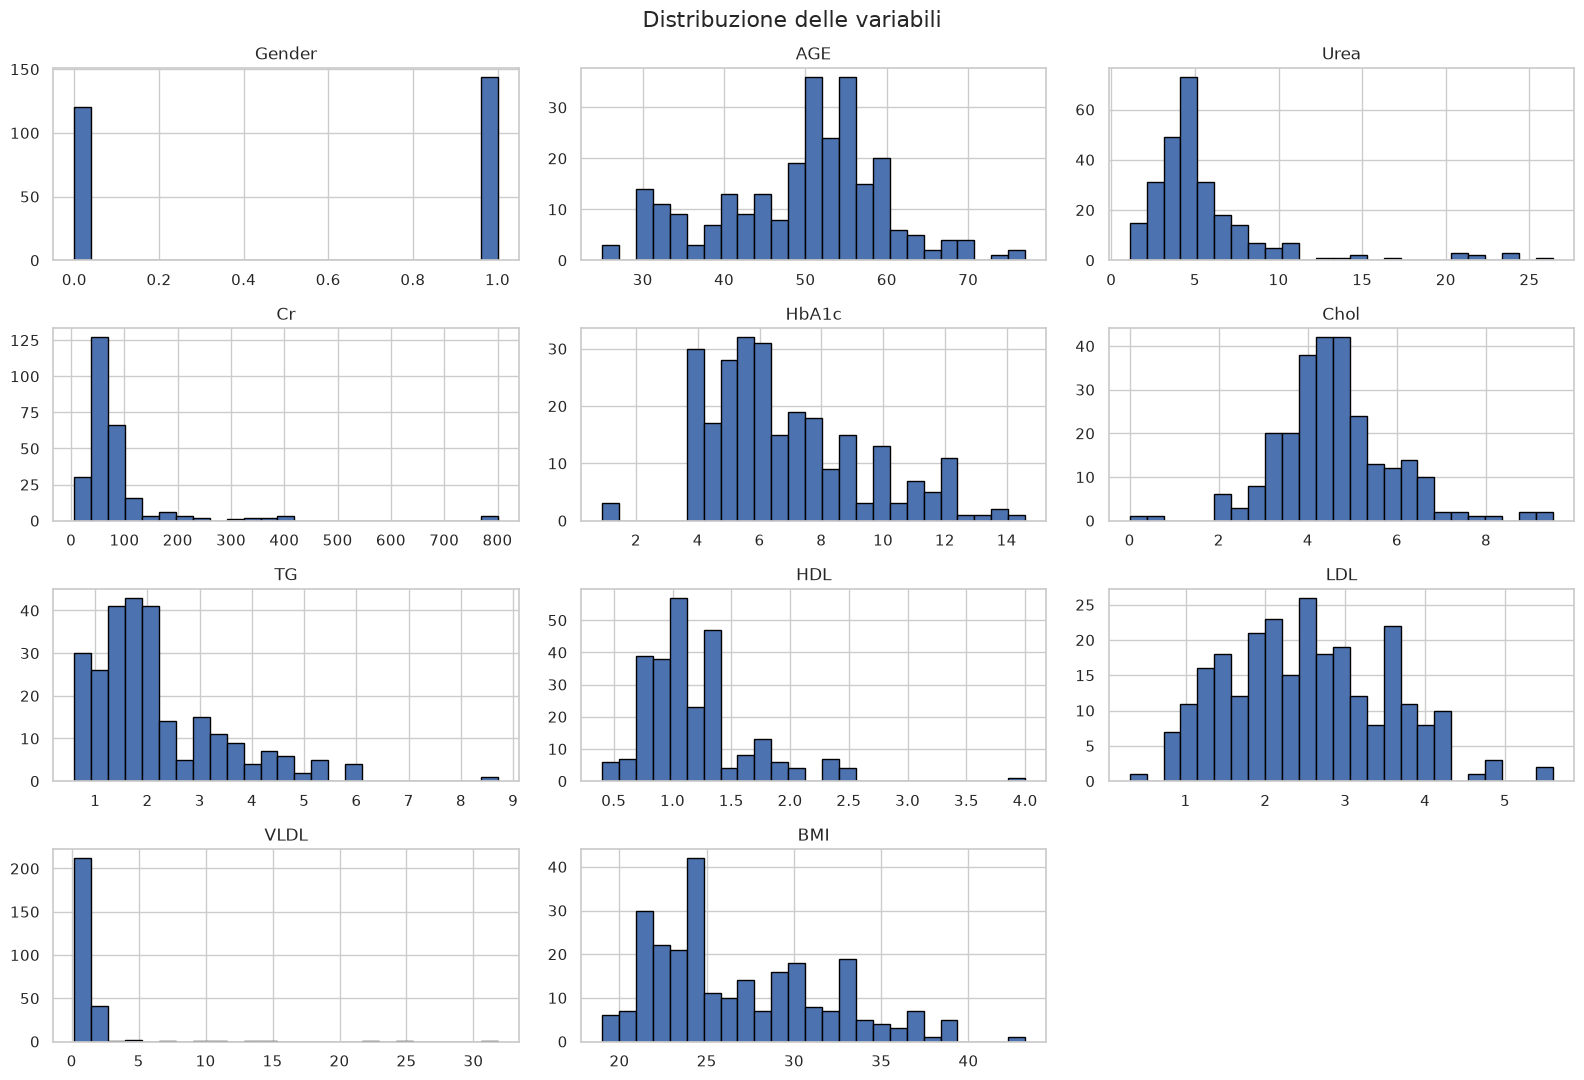

In [7]:
features = df.columns.drop(["HbA1c", "Class"])
target = "HbA1c"

df.drop(columns="Class").hist(bins=25, figsize=(16, 11), edgecolor="black")
plt.suptitle("Distribuzione delle variabili", fontsize=16)
plt.tight_layout()
plt.show()

- **HbA1c** ha una distribuzione bimodale: un gruppo intorno a 4-6% (non diabetici e prediabetici) e uno intorno a 7-13% (diabetici).
- **Cr**, **Urea**, **TG** e **VLDL** sono fortemente asimmetriche a destra.
- **AGE** è concentrata tra 40 e 60 anni, **BMI** tra 20 e 35.

**Boxplot** sulle feature standardizzate, per confrontarle sulla stessa scala e individuare gli outlier.

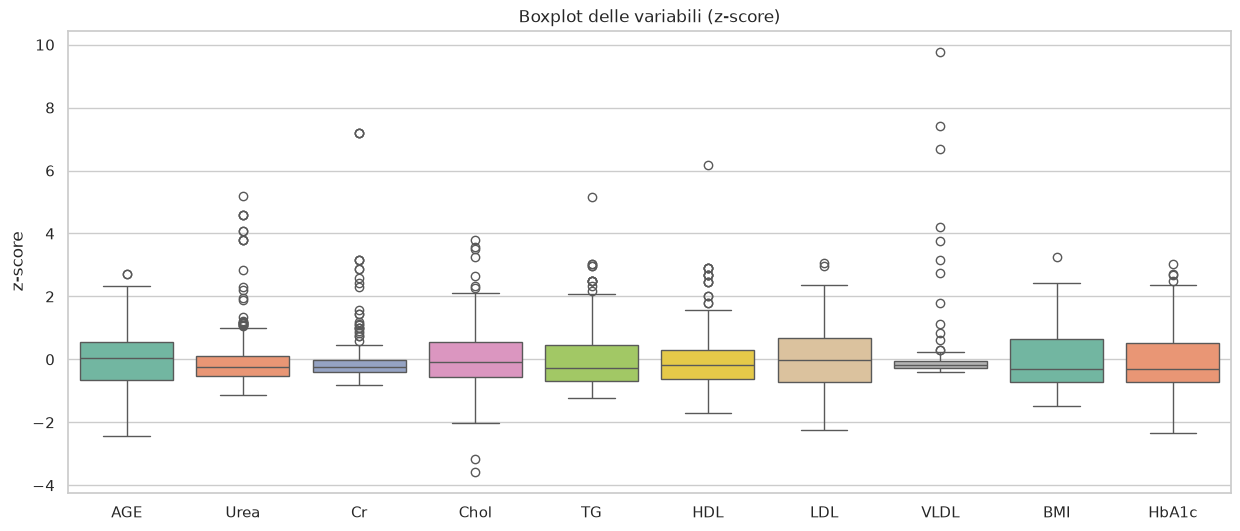

In [8]:
df_std = (df[list(features) + [target]] - df[list(features) + [target]].mean()) / df[list(features) + [target]].std()

plt.figure(figsize=(15, 6))
sns.boxplot(data=df_std.drop(columns="Gender"), palette="Set2")
plt.title("Boxplot delle variabili (z-score)")
plt.ylabel("z-score")
plt.show()

In [9]:
def conta_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

df.drop(columns=["Gender", "Class"]).apply(conta_outlier).rename("outlier (IQR)").to_frame().T

,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
outlier (IQR),2,25,25,4,9,12,16,2,13,1


Gli outlier più marcati sono in **Cr** (valori fino a 800, tipici di insufficienza renale), **VLDL** (fino a 31.8) e **Urea**. Nel target ci sono anche tre pazienti con HbA1c = 0.9%, un valore anomalo verso il basso.
Sono valori clinicamente possibili e il dataset è piccolo (264 righe), quindi ho deciso di **non rimuoverli**: eliminarli significherebbe perdere proprio i pazienti più critici. La standardizzazione e la cross-validation aiuteranno a capire quanto pesano sui modelli.

**Scatter matrix** sulle variabili più interessanti rispetto al target.

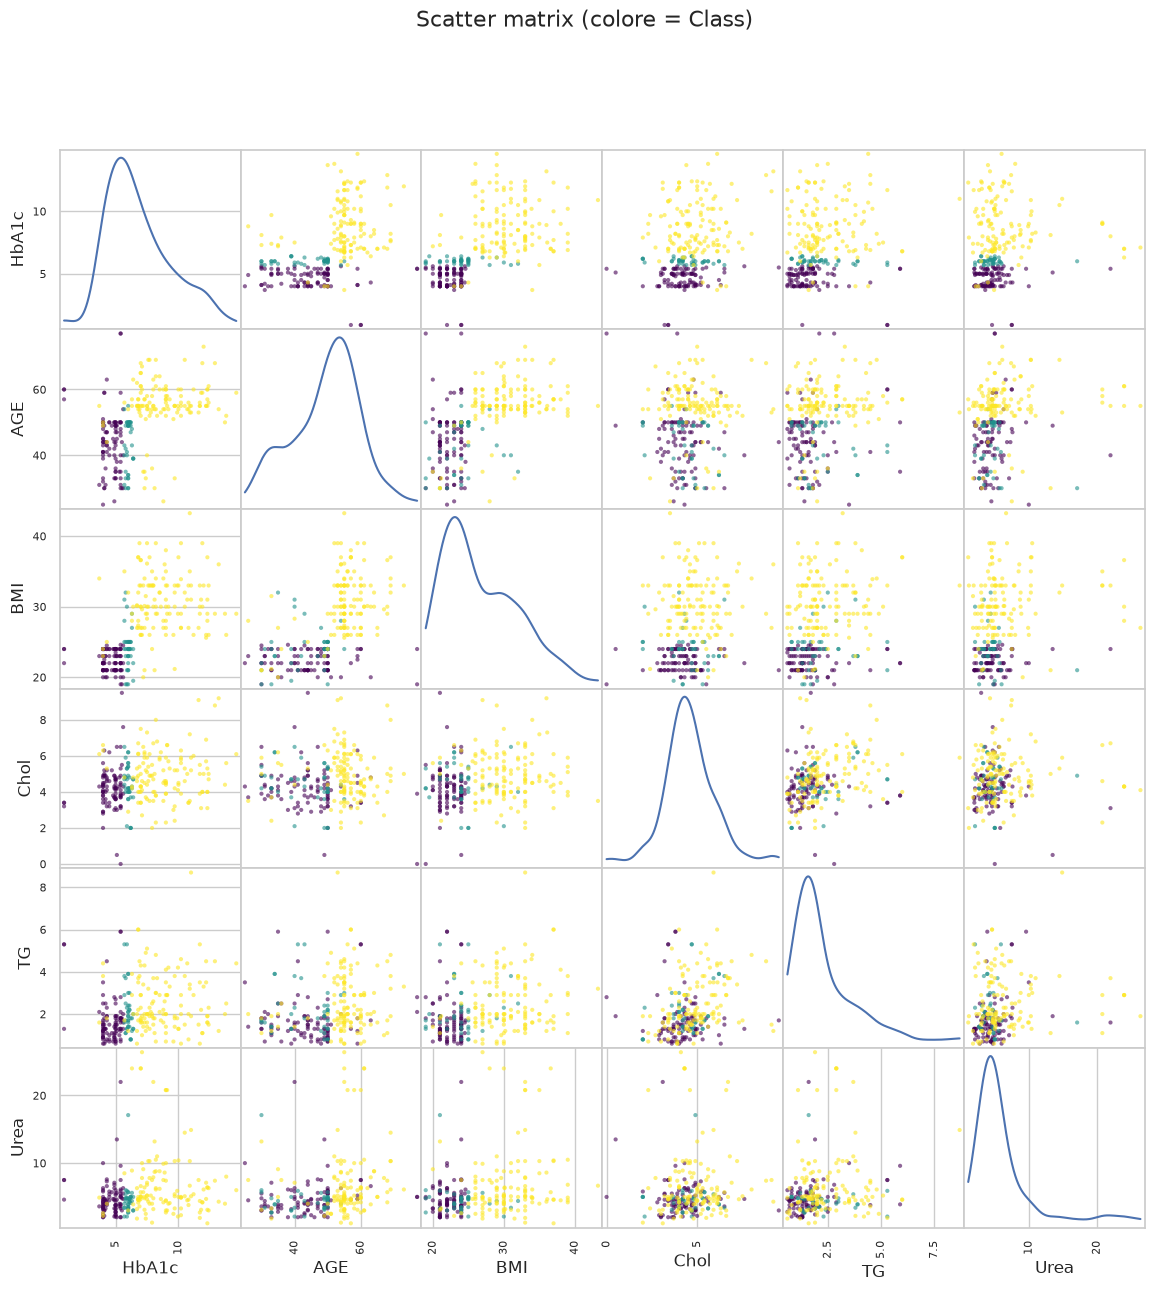

In [10]:
cols_sm = ["HbA1c", "AGE", "BMI", "Chol", "TG", "Urea"]
scatter_matrix(df[cols_sm], figsize=(14, 14), diagonal="kde", alpha=0.6, c=df["Class"], cmap="viridis")
plt.suptitle("Scatter matrix (colore = Class)", fontsize=16)
plt.show()

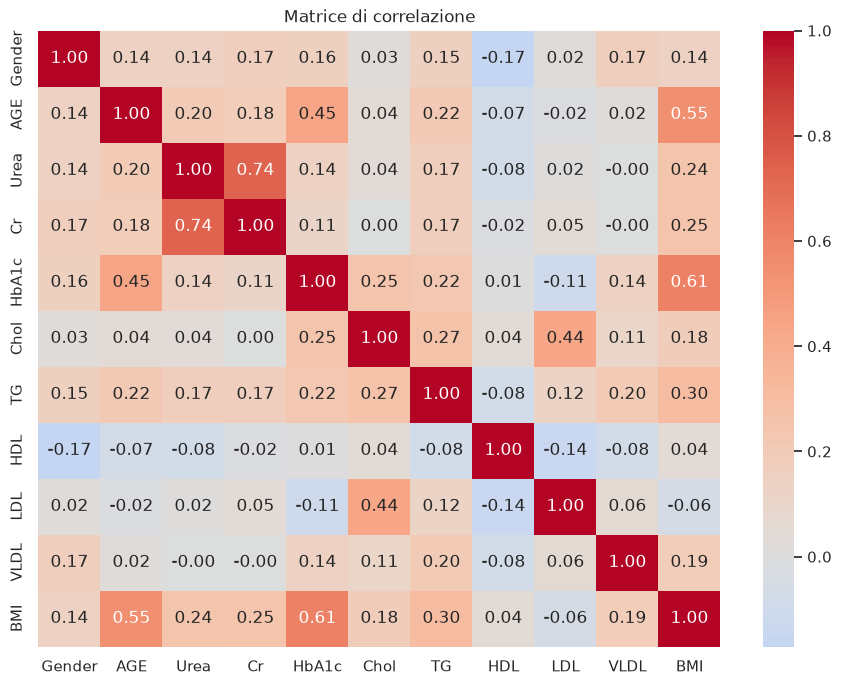

In [11]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.drop(columns="Class").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice di correlazione")
plt.show()

In [12]:
df.drop(columns="Class").corr()[target].drop(target).sort_values(key=abs, ascending=False).round(3)

BMI       0.615
AGE       0.447
Chol      0.251
TG        0.219
Gender    0.158
VLDL      0.144
Urea      0.140
Cr        0.114
LDL      -0.105
HDL       0.006
Name: HbA1c, dtype: float64

- Le feature più correlate con HbA1c sono **BMI** (0.61) e **AGE** (0.45): i pazienti diabetici del dataset sono in media più anziani e in sovrappeso.
- Seguono, con correlazioni deboli, **Chol** e **TG**; le altre feature hanno una relazione lineare quasi nulla con il target.
- Tra le feature la correlazione più alta è tra **Urea** e **Cr** (0.74), entrambe legate alla funzionalità renale; **Chol** e **LDL** sono moderatamente correlate (0.44). Non ci sono coppie così ridondanti da dover eliminare una feature.
- Dalla scatter matrix si vede che la relazione con il target non è perfettamente lineare: i gruppi sono abbastanza separati su BMI e AGE ma con molta dispersione.

### 1.3 Preparazione dei dati: Train / Test split

In [13]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)

Training set: (211, 10)
Test set:     (53, 10)


Ho usato l'80% dei dati per il training e il 20% per il test. La standardizzazione non viene applicata qui ma dentro una `Pipeline`, così lo scaler viene fittato solo sui dati di training di ogni fold e non ci sono informazioni del validation/test che "passano" nel training.

## 2. Confronto e Selezione Iniziale dei Modelli

Confronto i sei modelli con parametri di default, usando una **K-Fold Cross-Validation** con 10 fold sul solo training set e la metrica **NMSE** (`neg_mean_squared_error`): più il valore è vicino a 0, migliore è il modello.

In [14]:
modelli = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=SEED),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "KNN": KNeighborsRegressor(),
    "SVR": SVR(),
}

kfold = KFold(n_splits=10, shuffle=True, random_state=SEED)

risultati = {}
for nome, modello in modelli.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", modello)])
    scores = cross_val_score(pipe, X_train, y_train, cv=kfold, scoring="neg_mean_squared_error")
    risultati[nome] = scores
    print(f"{nome:<18} NMSE medio: {scores.mean():.4f}  (std: {scores.std():.4f})")

Linear Regression  NMSE medio: -4.0670  (std: 1.9451)
Decision Tree      NMSE medio: -4.9405  (std: 2.2700)
Ridge              NMSE medio: -4.0645  (std: 1.9522)


Lasso              NMSE medio: -5.2096  (std: 3.0404)
KNN                NMSE medio: -4.1220  (std: 2.2386)
SVR                NMSE medio: -4.1118  (std: 2.3224)


In [15]:
tabella = pd.DataFrame({
    "NMSE medio": {k: v.mean() for k, v in risultati.items()},
    "Std": {k: v.std() for k, v in risultati.items()},
    "RMSE medio": {k: np.sqrt(-v.mean()) for k, v in risultati.items()},
}).sort_values("NMSE medio", ascending=False)
tabella.round(4)

,NMSE medio,Std,RMSE medio
Ridge,-4.0645,1.9522,2.0161
Linear Regression,-4.0670,1.9451,2.0167
SVR,-4.1118,2.3224,2.0277
KNN,-4.1220,2.2386,2.0303
Decision Tree,-4.9405,2.2700,2.2227
Lasso,-5.2096,3.0404,2.2825


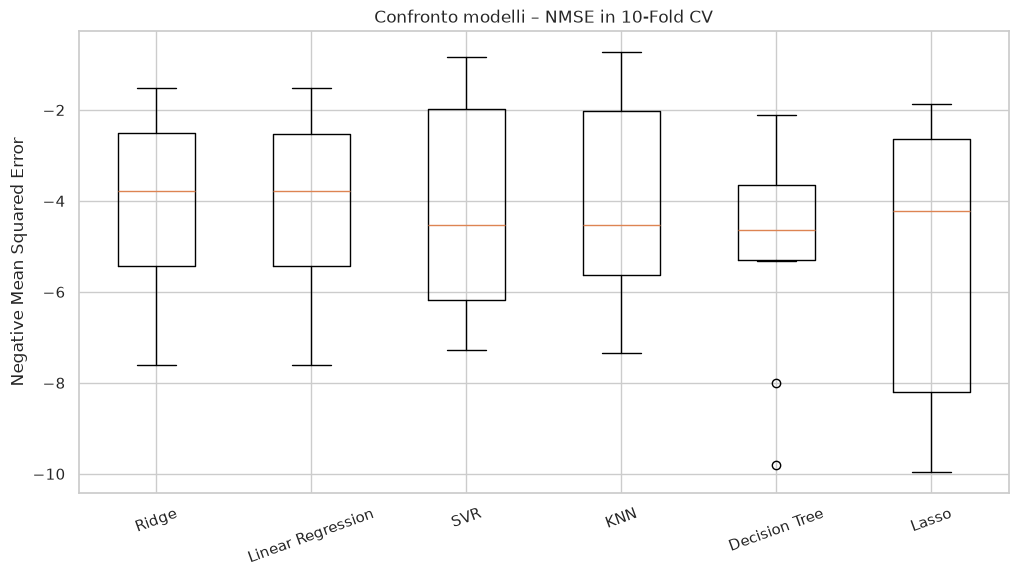

In [16]:
ordine = tabella.index
plt.figure(figsize=(12, 6))
plt.boxplot([risultati[k] for k in ordine], tick_labels=ordine)
plt.title("Confronto modelli – NMSE in 10-Fold CV")
plt.ylabel("Negative Mean Squared Error")
plt.xticks(rotation=20)
plt.show()

**Commento al confronto**

- **Ridge**, **Linear Regression**, **SVR** e **KNN** hanno prestazioni praticamente equivalenti (NMSE tra -4.06 e -4.12, RMSE ≈ 2.0 punti di HbA1c). La differenza tra loro è molto più piccola della deviazione standard tra i fold (≈ 2), quindi con parametri di default non c'è un vincitore netto.
- Ridge e Linear Regression danno quasi lo stesso risultato: con `alpha=1` la regolarizzazione è debole e le feature non sono molto collineari.
- **Lasso** è il peggiore: con `alpha=1` di default la penalità L1 è troppo forte e azzera quasi tutti i coefficienti, quindi il modello va in underfitting.
- **Decision Tree** senza limiti di profondità impara a memoria il training set (overfitting) e generalizza peggio.
- La varianza tra i fold è alta per tutti i modelli: il dataset è piccolo e gli outlier finiscono in fold diversi, facendo oscillare l'errore.

## 3. Hyperparameters Tuning

### 3.1 Grid Search

Tra i quattro modelli migliori, tutti statisticamente equivalenti, scelgo di ottimizzare il **K-Nearest Neighbor**:

- è un modello non lineare, adatto a un target bimodale come HbA1c e a relazioni che dalla scatter matrix non sembrano lineari;
- ha un iperparametro davvero cruciale, **`n_neighbors`**, che controlla direttamente il compromesso bias-varianza (k piccolo = modello molto flessibile, k grande = modello più liscio). Per Ridge invece cambiare `alpha` sposta poco il risultato, visto che Ridge e Linear Regression erano già quasi identici.

Cerco il valore di k migliore tra 1 e 30, sempre con 10-Fold CV e NMSE.

In [17]:
PARAM = "model__n_neighbors"
SCALA_X = "linear"

pipe_knn = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor())])
param_grid = {PARAM: list(range(1, 31))}

grid = GridSearchCV(pipe_knn, param_grid, cv=kfold, scoring="neg_mean_squared_error", return_train_score=True)

In [18]:
grid.fit(X_train, y_train)

print("Miglior parametro:", grid.best_params_)
print(f"Miglior NMSE (CV): {grid.best_score_:.4f}")

Miglior parametro: {'model__n_neighbors': 8}
Miglior NMSE (CV): -3.8117


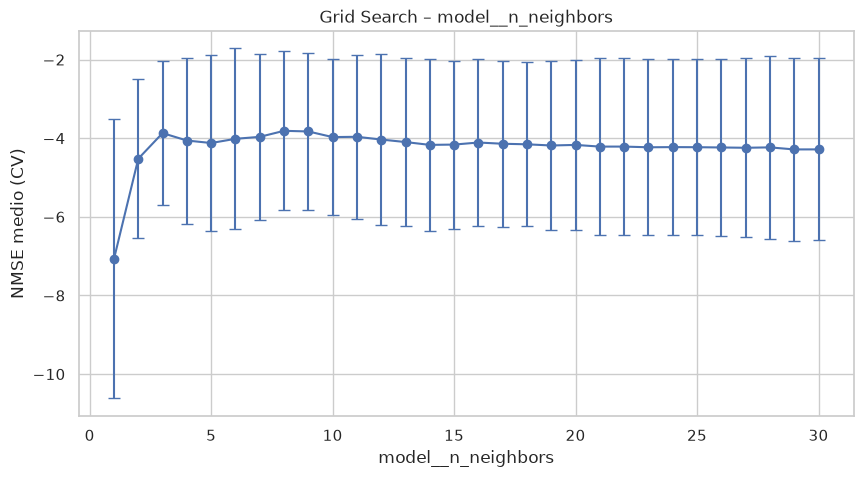

In [19]:
cv_res = pd.DataFrame(grid.cv_results_)
param_col = "param_" + PARAM

plt.figure(figsize=(10, 5))
plt.errorbar(cv_res[param_col].astype(float), cv_res["mean_test_score"], yerr=cv_res["std_test_score"], marker="o", capsize=4)
plt.xscale(SCALA_X)
plt.xlabel(PARAM)
plt.ylabel("NMSE medio (CV)")
plt.title(f"Grid Search – {PARAM}")
plt.show()

- Con **k = 1** l'errore è molto alto e instabile: il modello copia il vicino più vicino ed è sensibilissimo al rumore (overfitting).
- L'errore scende rapidamente e trova il minimo a **k = 8** (NMSE ≈ -3.81), migliore di tutti i modelli del confronto iniziale (-4.06 di Ridge).
- Per k > 10 la curva risale lentamente: la media su troppi vicini appiattisce le predizioni (underfitting).

### 3.2 Valutazione Finale sul Test set

In [20]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:.4f}")
print(f"RMSE: {np.sqrt(mse):.4f}")
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.4f}")
print(f"R2:   {r2:.4f}")

MSE:  2.6549
RMSE: 1.6294
MAE:  1.2455
R2:   0.5109


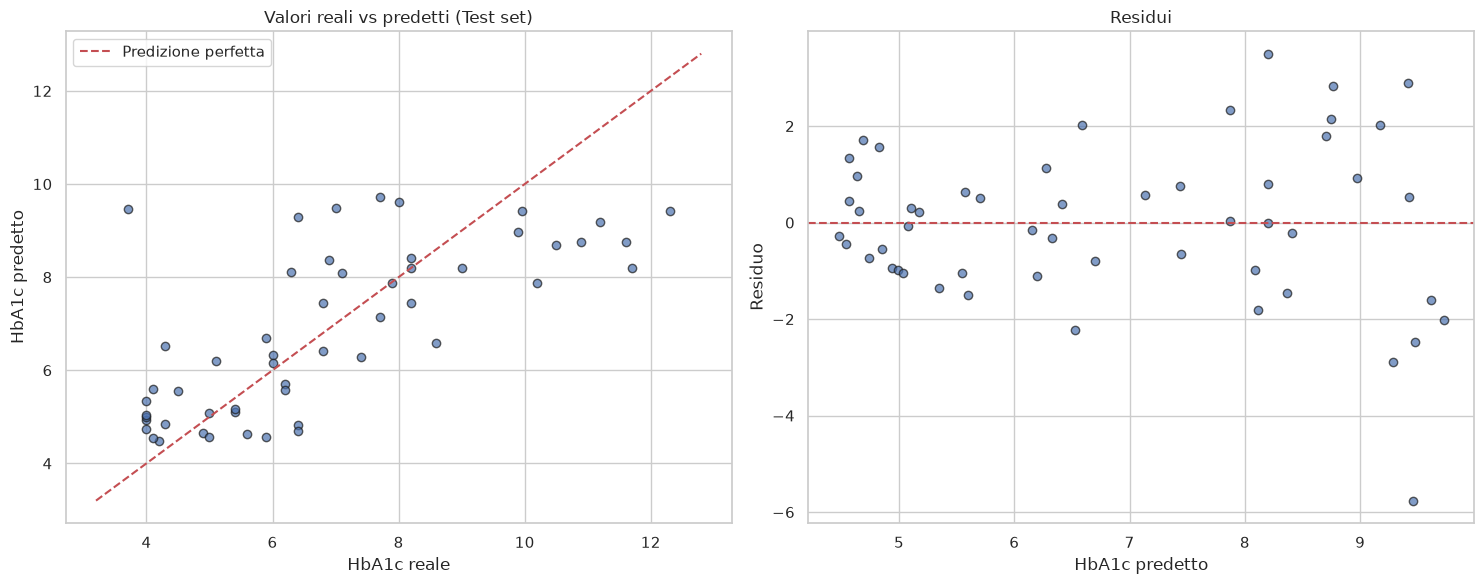

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

ax[0].scatter(y_test, y_pred, alpha=0.7, edgecolor="k")
lim = [min(y_test.min(), y_pred.min()) - 0.5, max(y_test.max(), y_pred.max()) + 0.5]
ax[0].plot(lim, lim, "r--", label="Predizione perfetta")
ax[0].set_xlabel("HbA1c reale")
ax[0].set_ylabel("HbA1c predetto")
ax[0].set_title("Valori reali vs predetti (Test set)")
ax[0].legend()

residui = y_test - y_pred
ax[1].scatter(y_pred, residui, alpha=0.7, edgecolor="k")
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("HbA1c predetto")
ax[1].set_ylabel("Residuo")
ax[1].set_title("Residui")

plt.tight_layout()
plt.show()

**Risultati sul Test set (KNN, k = 8):**

| Metrica | Valore |
|---|---|
| MSE | 2.65 |
| RMSE | 1.63 |
| MAE | 1.25 |
| R² | 0.51 |

- Il modello spiega circa il **51%** della varianza di HbA1c, con un errore medio di circa 1.2-1.6 punti percentuali.
- L'MSE sul test (2.65) è più basso di quello in cross-validation (3.81): il test set è piccolo (53 pazienti) e contiene pochi degli outlier più estremi, quindi la stima della CV è quella più prudente.
- Dal grafico reali vs predetti si vede che il modello tende a **sovrastimare i valori bassi e sottostimare quelli alti**: è l'effetto della media sui k vicini, che "comprime" le predizioni verso il centro. Per i diabetici con HbA1c sopra 10-11% l'errore è più grande.
- Un R² di 0.51 è ragionevole considerando che HbA1c dipende soprattutto dalla glicemia, che nel dataset non è presente: le feature disponibili (età, BMI, profilo lipidico, funzionalità renale) danno solo un'informazione indiretta.

## 4. Analisi delle Performance

### 4.1 Learning Curves

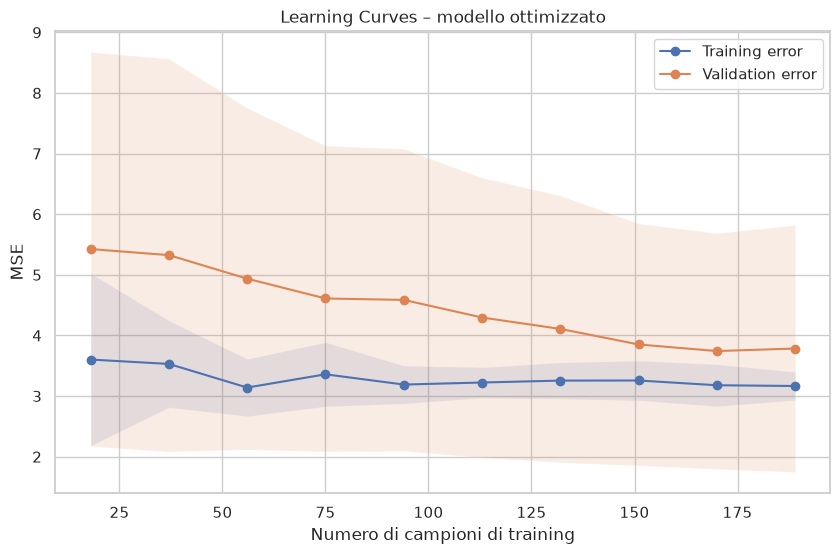

MSE training finale:   3.1664
MSE validation finale: 3.7846
Gap:                   0.6182


In [22]:
train_sizes, train_scores, val_scores = learning_curve(
    best_model, X_train, y_train,
    cv=kfold, scoring="neg_mean_squared_error",
    train_sizes=np.linspace(0.1, 1.0, 10), random_state=SEED, shuffle=True
)

train_mse = -train_scores.mean(axis=1)
val_mse = -val_scores.mean(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mse, "o-", label="Training error")
plt.fill_between(train_sizes, train_mse - train_scores.std(axis=1), train_mse + train_scores.std(axis=1), alpha=0.15)
plt.plot(train_sizes, val_mse, "o-", label="Validation error")
plt.fill_between(train_sizes, val_mse - val_scores.std(axis=1), val_mse + val_scores.std(axis=1), alpha=0.15)
plt.xlabel("Numero di campioni di training")
plt.ylabel("MSE")
plt.title("Learning Curves – modello ottimizzato")
plt.legend()
plt.show()

print(f"MSE training finale:   {train_mse[-1]:.4f}")
print(f"MSE validation finale: {val_mse[-1]:.4f}")
print(f"Gap:                   {val_mse[-1] - train_mse[-1]:.4f}")

**Analisi bias-varianza**

- La **validation error** scende man mano che aumentano i campioni (da ≈ 5.4 a ≈ 3.8): il modello beneficia di più dati.
- La **training error** resta stabile intorno a 3.2 e non è vicina a zero: con k = 8 il modello non memorizza il training set.
- Alla fine il **gap** tra le due curve è piccolo (≈ 0.6), quindi la **varianza è contenuta** e non c'è overfitting.
- L'errore di entrambe le curve rimane però relativamente alto (MSE ≈ 3-4): la componente principale dell'errore è il **bias**. Il modello tende quindi leggermente all'**underfitting**, dovuto più ai limiti delle feature che alla complessità del modello.
- Le curve non sono ancora del tutto piatte e la banda della validation è molto ampia: con più dati l'errore di validazione potrebbe ancora scendere un po' e diventare più stabile.

## 5. Visualizzazione con Data Reduction

### 5.1 PCA a due componenti

In [23]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_sc)
X_test_pca = pca.transform(X_test_sc)

print("Varianza spiegata:", pca.explained_variance_ratio_.round(3))
print(f"Totale: {pca.explained_variance_ratio_.sum():.3f}")

Varianza spiegata: [0.242 0.161]
Totale: 0.403


In [24]:
loadings = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"])
loadings.round(3).sort_values("PC1", key=abs, ascending=False)

,PC1,PC2
BMI,0.442,-0.071
Cr,0.424,-0.382
Urea,0.413,-0.375
AGE,0.361,-0.117
TG,0.361,0.277
Gender,0.269,0.100
Chol,0.208,0.507
VLDL,0.175,0.296
LDL,0.171,0.479
HDL,-0.136,-0.183


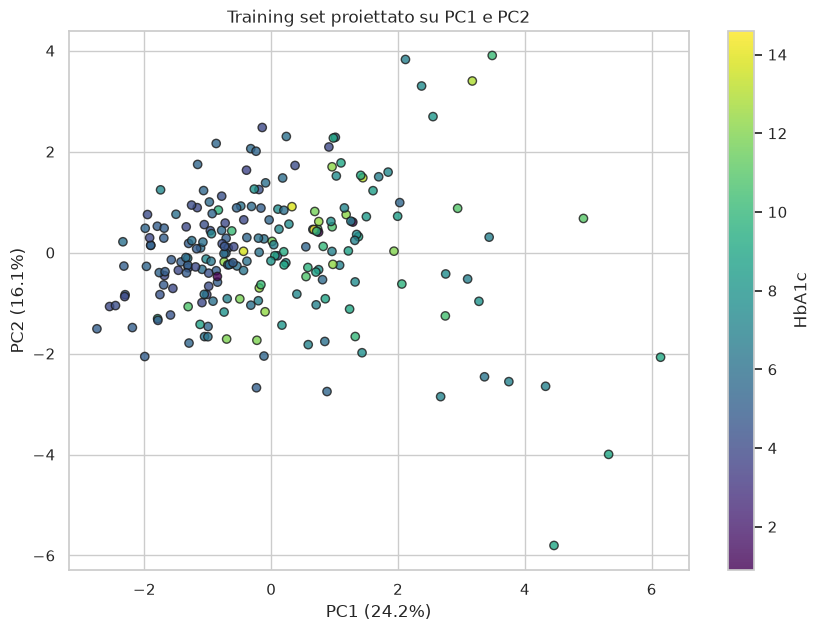

In [25]:
fig, ax = plt.subplots(figsize=(10, 7))
sc = ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap="viridis", edgecolor="k", alpha=0.8)
plt.colorbar(sc, label="HbA1c")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("Training set proiettato su PC1 e PC2")
plt.show()

- Le prime due componenti spiegano circa il **40%** della varianza totale (24% + 16%): una riduzione abbastanza forte, perché le 10 feature sono poco correlate tra loro.
- **PC1** ha pesi positivi su quasi tutte le variabili, soprattutto **BMI, Cr, Urea, AGE e TG**: rappresenta un "profilo di rischio" generale (pazienti più anziani, in sovrappeso, con valori renali e lipidici alti).
- **PC2** contrappone il profilo lipidico (**Chol, LDL, VLDL**, positivi) alla funzionalità renale (**Cr, Urea**, negativi).
- Nel grafico i valori alti di HbA1c (giallo) si concentrano verso destra, cioè per PC1 alta, mentre lungo PC2 non c'è un andamento chiaro.

### 5.2 Plot della Regressione

Riaddestro il modello ottimizzato (stesso algoritmo e stesso iperparametro trovato con la Grid Search) usando come input solo PC1 e PC2, così da poter disegnare la superficie di regressione in 3D.

In [26]:
from sklearn.base import clone

model_2d = clone(best_model.named_steps["model"])
model_2d.fit(X_train_pca, y_train)

y_pred_2d = model_2d.predict(X_test_pca)
print(f"Modello su PC1-PC2 -> MSE test: {mean_squared_error(y_test, y_pred_2d):.4f}  R2 test: {r2_score(y_test, y_pred_2d):.4f}")

Modello su PC1-PC2 -> MSE test: 4.0176  R2 test: 0.2598


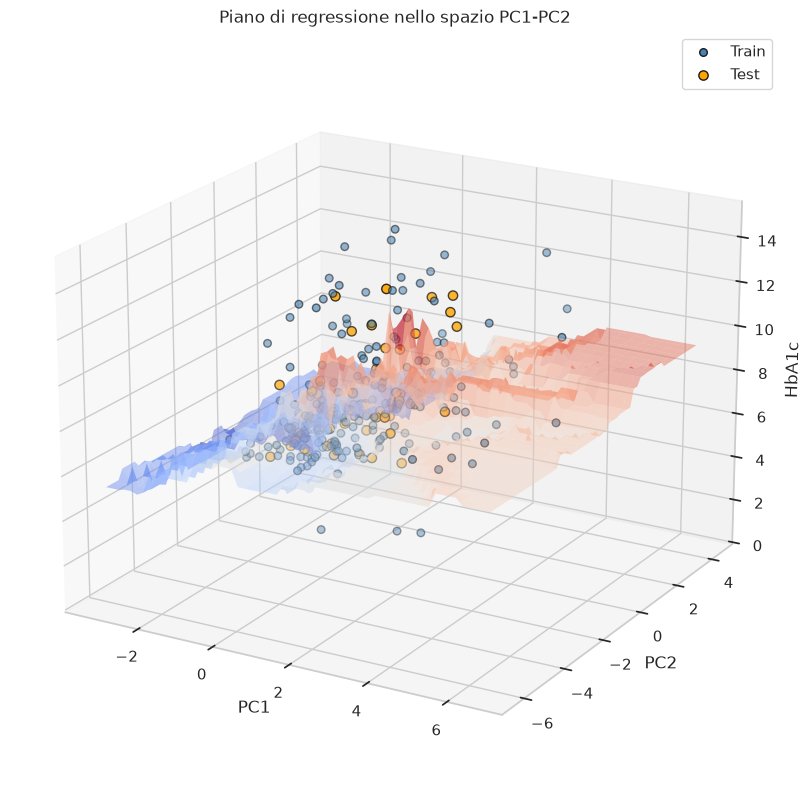

In [27]:
x1 = np.linspace(X_train_pca[:, 0].min() - 0.5, X_train_pca[:, 0].max() + 0.5, 60)
x2 = np.linspace(X_train_pca[:, 1].min() - 0.5, X_train_pca[:, 1].max() + 0.5, 60)
G1, G2 = np.meshgrid(x1, x2)
Z = model_2d.predict(np.c_[G1.ravel(), G2.ravel()]).reshape(G1.shape)

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(G1, G2, Z, cmap="coolwarm", alpha=0.45, edgecolor="none")
ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], y_train, c="steelblue", edgecolor="k", s=30, label="Train")
ax.scatter(X_test_pca[:, 0], X_test_pca[:, 1], y_test, c="orange", edgecolor="k", s=45, label="Test")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("HbA1c")
ax.set_title("Piano di regressione nello spazio PC1-PC2")
ax.view_init(elev=20, azim=-60)
ax.legend()
plt.show()

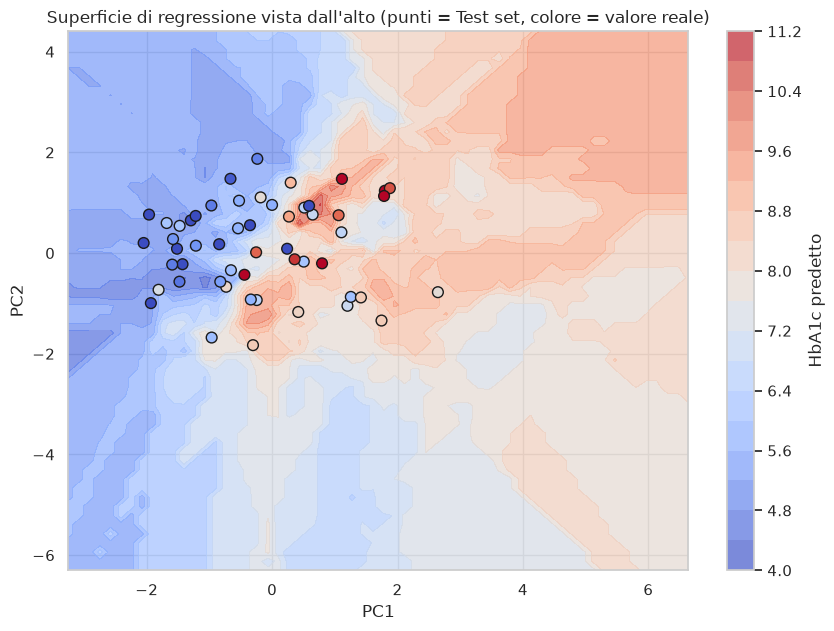

In [28]:
plt.figure(figsize=(10, 7))
cf = plt.contourf(G1, G2, Z, levels=20, cmap="coolwarm", alpha=0.7)
plt.colorbar(cf, label="HbA1c predetto")
plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap="coolwarm", edgecolor="k", s=60,
            vmin=Z.min(), vmax=Z.max())
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Superficie di regressione vista dall'alto (punti = Test set, colore = valore reale)")
plt.show()

- Poiché il modello ottimizzato è un KNN, la "superficie" di regressione non è un piano liscio come quello di una regressione lineare ma una superficie a gradini: ogni punto della griglia prende la media di HbA1c dei suoi 8 vicini.
- La superficie cresce chiaramente lungo **PC1**: si passa da valori intorno a 4-5% (blu) a valori di 8-10% (rosso) per PC1 alta, in linea con quanto visto nella PCA.
- Lungo **PC2** la variazione è molto più debole.
- Usando solo due componenti l'R² sul test scende da 0.51 a circa 0.26: la proiezione in 2D perde parte dell'informazione utile, quindi questo grafico serve per **visualizzare** il comportamento del modello, mentre per le predizioni conviene usare tutte le feature.

## Conclusioni

- Il dataset è pulito (nessun valore nullo o duplicato) ma piccolo e con diversi outlier clinicamente plausibili, che sono stati mantenuti.
- Come target è stato scelto **HbA1c**, escludendo la colonna `Class` per evitare data leakage.
- Nel confronto iniziale con 10-Fold CV, Ridge, Linear Regression, SVR e KNN hanno ottenuto risultati simili, mentre Lasso (penalità troppo forte) e Decision Tree (overfitting) sono risultati i peggiori.
- Dopo la Grid Search su `n_neighbors`, il **KNN con k = 8** è diventato il modello migliore (NMSE CV ≈ -3.81), con **MSE = 2.65** e **R² = 0.51** sul test set.
- Le learning curves mostrano una varianza bassa e un bias moderato: il limite principale non è il modello ma l'informazione contenuta nelle feature, perché manca la glicemia, che è la variabile più legata a HbA1c.
- La PCA mostra che la prima componente, legata a BMI, età e valori renali/lipidici, è quella che guida la predizione di HbA1c.